<a href="https://colab.research.google.com/github/DobryCzlowiekDobryKodzik/Traffic-Sign-Recognition/blob/main/notebooks/etap_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Etap 2 – Implementacja potoku przetwarzania obrazów


## 1. Wczytywanie danych

W pierwszym kroku przygotowano mechanizm automatycznego wczytywania zdjęć znaków drogowych z Dysku Google. Zdjęcia zostały podzielone na foldery odpowiadające rozpoznawanym znakom oraz pozostałym znakom drogowym.

https://drive.google.com/drive/folders/1qgMNpPgJHUDNbFQr3L3fJr9prOsZ97U5?usp=drive_link

In [ ]:
from google.colab import drive
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

drive.mount('/content/drive')

In [ ]:

DATA_DIR = Path('/content/drive/MyDrive/Zdjęcia-projekt')

In [ ]:
# Etykiety rozpoznawanych znaków
klasy = {
    "zakazu": "zakazu",
    "nakazu": "nakazu",
    "ostrzegawcze": "ostrzegawcze",
    # "inne": "Inny znak"
}

rozszerzenia = {".jpg", ".jpeg", ".png"}
dane = []

for folder, etykieta in klasy.items():
    sciezka_folderu = DATA_DIR / folder

    if not sciezka_folderu.exists():
        print(f"Brak folderu: {sciezka_folderu}")
        continue

    for plik in sorted(sciezka_folderu.rglob("*")):
        if plik.suffix.lower() not in rozszerzenia:
            continue

        obraz = cv2.imread(str(plik))

        if obraz is None:
            print(f"Nie udało się wczytać: {plik.name}")
            continue

        dane.append({
            "plik": plik.name,
            "sciezka": str(plik),
            "etykieta": etykieta,
            "szerokosc": obraz.shape[1],
            "wysokosc": obraz.shape[0]
        })

df_zdjecia = pd.DataFrame(dane)

print(f"Wczytano {len(df_zdjecia)} zdjęć.")
display(df_zdjecia)

In [ ]:
if len(df_zdjecia) > 0:
    probka = df_zdjecia.sample(
        n=min(6, len(df_zdjecia)),
        random_state=42
    )

    fig, axes = plt.subplots(
        1, len(probka),
        figsize=(4 * len(probka), 4),
        squeeze=False
    )

    for ax, (_, wiersz) in zip(axes[0], probka.iterrows()):
        obraz = cv2.imread(wiersz["sciezka"])
        obraz_rgb = cv2.cvtColor(obraz, cv2.COLOR_BGR2RGB)

        ax.imshow(obraz_rgb)
        ax.set_title(wiersz["etykieta"])
        ax.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Nie znaleziono zdjęć. Sprawdź ścieżkę DATA_DIR.")

In [ ]:
wczytane = cv2.imread(df_zdjecia.loc[78, "sciezka"])

plt.figure(figsize=(10, 12))
plt.imshow(cv2.cvtColor(wczytane, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

## 2. Przetwarzanie wstępne obrazów

Celem przetwarzania wstępnego jest przygotowanie obrazów do dalszej segmentacji i ekstrakcji cech znaków drogowych. Zastosowano następujące operacje:

1. **Skalowanie proporcjonalne** – zmniejszenie rozdzielczości obrazów z zachowaniem ich oryginalnych proporcji. Maksymalny wymiar obrazu ustalono na 800 pikseli.
2. **Filtracja Gaussa** – zastosowanie filtra o rozmiarze 5×5 w celu redukcji szumów i niewielkich zakłóceń obrazu.
3. **Korekcja kontrastu CLAHE (opcjonalnie)** – lokalne wyrównanie kontrastu w kanale jasności przestrzeni Lab, poprawiające widoczność szczegółów w nierównomiernych warunkach oświetlenia.

Zastosowanie CLAHE będzie oceniane na podstawie porównania wyników przetwarzania i segmentacji obrazów.

In [ ]:
def skaluj_proporcjonalnie(obraz, max_wymiar=800):
    h, w = obraz.shape[:2]

    # Zachowanie proporcji i unikanie powiększania małych obrazów
    skala = min(max_wymiar / max(h, w), 1.0)

    nowa_szerokosc = max(1, int(round(w * skala)))
    nowa_wysokosc = max(1, int(round(h * skala)))

    return cv2.resize(
        obraz,
        (nowa_szerokosc, nowa_wysokosc),
        interpolation=cv2.INTER_AREA
    )


def przetwarzanie_wstepne(obraz, prog_jasnosci = 80):
    # 1. Skalowanie proporcjonalne
    obraz = skaluj_proporcjonalnie(obraz)

    # 2. Filtr Gaussa 5x5
    obraz = cv2.GaussianBlur(obraz, (5, 5), 0)

    # 3. Opcjonalna korekcja kontrastu CLAHE

    lab = cv2.cvtColor(obraz, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    median = np.median(l)
    procent_ciemnych = np.mean(l < 50) * 100

    # print(median)
    # print(procent_ciemnych)

    if median < prog_jasnosci:

        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )

        l = clahe.apply(l)

        lab = cv2.merge((l, a, b))
        obraz = cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)

    return obraz

In [ ]:
przetworzone = []
for indeks,i in df_zdjecia.iterrows():
  obraz = cv2.imread(i["sciezka"])
  obraz = przetwarzanie_wstepne(obraz)
  przetworzone.append(obraz)


In [ ]:
plt.figure(figsize=(10, 12))
plt.imshow(cv2.cvtColor(przetworzone[160], cv2.COLOR_BGR2RGB))


## 3. Konwersja przestrzeni barw

In [ ]:
hsv = []
for i in przetworzone:
  obraz = cv2.cvtColor(i,cv2.COLOR_BGR2HSV)
  hsv.append(obraz)

Dla wygody pracy pracy zrobię słownik znaków wraz z ich etykietami


## 4. Segmentacja kolorów

### Defnicja przedziałów hsv

In [ ]:
dolna_czerwien1 = np.array([0, 80, 50])
gorna_czerwien1 = np.array([10, 255, 255])

dolna_czerwien2 = np.array([170, 80, 50])
gorna_czerwien2 = np.array([179, 255, 255])

dolna_niebieski = np.array([100,  130, 50])
gorna_niebieski = np.array([125,  255, 255])

# dolna_zolta = np.array([10, 100 , 70])
# gorna_zolta = np.array([35,  255, 255])

# dolna_zolta = np.array([5, 100 , 70])
# gorna_zolta = np.array([45,  255, 255])

# dolna_zolta = np.array([15, 80, 70])
# gorna_zolta = np.array([35, 255, 255])

dolna_zolta = np.array([5, 100, 70])
gorna_zolta = np.array([35, 255, 255])

### Maska niebieska - wizualizacja

In [ ]:
plt.imshow(cv2.inRange(hsv[79],dolna_niebieski,gorna_niebieski),cmap="gray")



### Maska czerwona - wizualizacja

In [ ]:
maska1 = cv2.inRange(hsv[160], dolna_czerwien1, gorna_czerwien1)
maska2 = cv2.inRange(hsv[160], dolna_czerwien2, gorna_czerwien2)

maska_czerwona = cv2.bitwise_or(maska1, maska2)

plt.imshow(maska_czerwona, cmap="gray")
plt.show()

### Maska żółta - wizualizacja

In [ ]:
plt.imshow(cv2.inRange(hsv[160],dolna_zolta,gorna_zolta),cmap="gray")

### Generowanie masek

In [ ]:
def tworzenie_masek(obraz):

  maska1 = cv2.inRange(obraz, dolna_czerwien1, gorna_czerwien1)
  maska2 = cv2.inRange(obraz, dolna_czerwien2, gorna_czerwien2)

  maska_czerwona = cv2.bitwise_or(maska1, maska2)

  maska_niebieska = cv2.inRange(obraz,dolna_niebieski,gorna_niebieski)

  maska_zolta = cv2.inRange(obraz,dolna_zolta,gorna_zolta)

  return maska_czerwona,maska_niebieska,maska_zolta

In [ ]:
wszystkie_maski = []
for i in hsv:
  wszystkie_maski.append(tworzenie_masek(i))


## 5. Oczyszczanie masek

In [ ]:
kernel_3 = np.ones((3, 3), dtype=np.uint8)
kernel_5 = np.ones((5, 5), dtype=np.uint8)
def oczyszczanie_maski(maska):
  maska = cv2.morphologyEx(maska,cv2.MORPH_OPEN,kernel_3)
  maska = cv2.morphologyEx(maska,cv2.MORPH_CLOSE,kernel_3)
  return maska

###Wizualizacja oczyszczonych masek

In [ ]:
plt.figure(figsize=(10, 12))
plt.subplot(3,2,1)
plt.imshow(wszystkie_maski[0][0],cmap="gray")
plt.subplot(3,2,2)
plt.imshow(oczyszczanie_maski(wszystkie_maski[0][0]),cmap="gray")
plt.subplot(3,2,3)
plt.imshow(wszystkie_maski[79][1],cmap="gray")
plt.subplot(3,2,4)
plt.imshow(oczyszczanie_maski(wszystkie_maski[79][1]),cmap="gray")
plt.subplot(3,2,5)
plt.imshow(wszystkie_maski[161][2],cmap="gray")
plt.subplot(3,2,6)
plt.imshow(oczyszczanie_maski(wszystkie_maski[161][2]),cmap="gray")
plt.tight_layout()

### Oczyszczanie masek

In [ ]:
wszystkie_maski_oczyszczone = []
for zestaw_masek in wszystkie_maski:
  maska_czerwona = oczyszczanie_maski(zestaw_masek[0])
  maska_niebieska = oczyszczanie_maski(zestaw_masek[1])
  maska_zolta = oczyszczanie_maski(zestaw_masek[2])
  wszystkie_maski_oczyszczone.append(
      [maska_czerwona, maska_niebieska, maska_zolta]
      )


## 6. Wykrywanie kandydatów / ROI

###Wykrywanie konturów oraz anliza ich powierzchni
Wykrywamy wszystkie kontury zewnętrzne a nastepnie usuwamy te których powierzchnia stanowi mniej niż 0,02% zdjęcia

In [ ]:
kontury = []
for maski in wszystkie_maski_oczyszczone:
  kontur_czerwony,_ =  cv2.findContours(maski[0],cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
  kontur_niebieski,_ =  cv2.findContours(maski[1],cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
  kontur_zolty,_ =  cv2.findContours(maski[2],cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

  # odsiewamy konury o powierzni miejszej niż 0,1% całej maski
  prog = maski[0].shape[0] * maski[0].shape[1] * 0.001

  #konury z maski czerwonej
  kontury_czerwone_filtrowane = []
  for kontur in kontur_czerwony:
    if cv2.contourArea(kontur) >= prog:
      kontury_czerwone_filtrowane.append(kontur)
  #konury z maski niebieskiej
  kontury_niebieskie_filtrowane = []
  for kontur in kontur_niebieski:
    if cv2.contourArea(kontur) >= prog:
      kontury_niebieskie_filtrowane.append(kontur)
  #konury z maski zoltej
  kontury_zolte_filtrowane = []
  for kontur in kontur_zolty:
    if cv2.contourArea(kontur) >= prog:
      kontury_zolte_filtrowane.append(kontur)
  kontury.append(
      [kontury_czerwone_filtrowane,kontury_niebieskie_filtrowane,kontury_zolte_filtrowane]
  )


###Wizualizacja konturów po oczyszczeniu

In [ ]:
maska_po_filtracji = np.zeros_like(wszystkie_maski_oczyszczone[0][0])
cv2.drawContours(maska_po_filtracji,kontury[0][0],-1,(255,0,0),1)

In [ ]:
maska_po_filtracji = np.zeros_like(wszystkie_maski_oczyszczone[85][1])
cv2.drawContours(maska_po_filtracji,kontury[85][1],-1,(255,0,0),1)

In [ ]:
maska_po_filtracji = np.zeros_like(wszystkie_maski_oczyszczone[150][2])
cv2.drawContours(maska_po_filtracji,kontury[150][2],-1,(255,0,0),1)

### Przybliżenie kształtu konturu

In [ ]:
przyblizony_kontur = []
for kontur in kontury[0][0]:
  przyblizony_kontur.append(cv2.approxPolyDP(kontur, cv2.arcLength(kontur, True) * 0.02, True))
  # print(len(cv2.approxPolyDP(kontur, cv2.arcLength(kontur, True) * 0.01, True)))
kopia_zdjęcia = np.zeros_like(wszystkie_maski_oczyszczone[0][0])
cv2.drawContours(kopia_zdjęcia,przyblizony_kontur,-1,255,1)


In [ ]:
przyblizony_kontur = []
for kontur in kontury[59][1]:
  przyblizony_kontur.append(cv2.approxPolyDP(kontur, cv2.arcLength(kontur, True) * 0.02, True))
kopia_zdjęcia = np.zeros_like(wszystkie_maski_oczyszczone[14][1])
cv2.drawContours(kopia_zdjęcia,przyblizony_kontur,-1,255,1)

In [ ]:
przyblizony_kontur = []
for kontur in kontury[20][2]:
  przyblizony_kontur.append(cv2.approxPolyDP(kontur, cv2.arcLength(kontur, True) * 0.02, True))
kopia_zdjęcia = np.zeros_like(wszystkie_maski_oczyszczone[20][2])
cv2.drawContours(kopia_zdjęcia,przyblizony_kontur,-1,255,1)


Przybliżanie konturu w obecnej formie nie daje zamierzonych efektów

### Wyznaczanie obszaru ROI

In [ ]:
obszary_roi = []

for i, zestaw_konturow in enumerate(kontury):
    roi_zdjecia = []

    for kolor, lista_konturow in enumerate(zestaw_konturow):
        for kontur in lista_konturow:

            x, y, w, h = cv2.boundingRect(kontur)

            roi = przetworzone[i][y:y+h, x:x+w]

            roi_zdjecia.append({

                "kolor": kolor,
                "kontur": kontur,
                "x": x,
                "y": y,
                "w": w,
                "h": h,
                "roi": roi
            })

    obszary_roi.append(roi_zdjecia)

### Wizualizacja wszystkich roi zakazu

In [ ]:
nazwy_masek = {
    0: "Czerwona",
    1: "Niebieska",
    2: "Żółta"
}

for id_zdjecia in range(0, 75):

    roi_zdjecia = obszary_roi[id_zdjecia]

    if len(roi_zdjecia) == 0:
        print(f"Zdjęcie {id_zdjecia}: brak wykrytych ROI")
        continue

    kolumny = 5
    wiersze = math.ceil(len(roi_zdjecia) / kolumny)

    fig, axes = plt.subplots(
        wiersze, kolumny,
        figsize=(16, wiersze * 2.5),
        squeeze=False
    )

    fig.suptitle(
        f"Zdjęcie {id_zdjecia} — wykryte ROI: {len(roi_zdjecia)}",
        fontsize=14
    )

    for i, ax in enumerate(axes.flat):

        if i < len(roi_zdjecia):
            roi = roi_zdjecia[i]["roi"]
            kolor = roi_zdjecia[i]["kolor"]

            maska = nazwy_masek.get(kolor, "Nieznana")

            ax.imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))

            ax.set_title(
                f"Zdjęcie {id_zdjecia} | ROI {i}\n"
                f"Maska: {maska}",
                fontsize=9
            )

        ax.axis("off")

    plt.tight_layout()
    plt.show()
    plt.close(fig)


### Etykietowanie roi zakazu

In [ ]:

# (indeks_zdjecia, indeks_roi, etykieta)
wybrane_roi_zakazu =[
    (0, 2, "B-20"),
    (1, 0, "B-20"),
    (2, 0, "B-20"),
    (3, 7, "Inny znak"),
    (4, 2, "B-20"),
    (5, 2, "B-20"),
    (6, 1, "B-20"),
    (7, 0, "B-20"),
    (8, 6, "B-20"),
    (9, 1, "B-20"),
    (10, 0, "Inny znak"),
    (11, 2, "Inny znak"),
    (12, 3, "Inny znak"),
    (13, 1, "Inny znak"),
    (14, 1, "Inny znak"),
    # (15, 0, "B-20"),
    (16, 6, "B-20"),
    (17, 10, "B-20"),
    (18, 3, "B-20"),
    (19, 3, "B-20"),
    (20, 3, "B-20"),
    (21, 2, "B-20"),
    (22, 2, "B-20"),
    # (23, 0, "B-20"),
    # (24, 0, "B-20"),
    (25, 5, "B-20"),
    (26, 3, "B-20"),
    (27, 0, "B-20"),
    (28, 4, "B-20"),
    (29, 6, "B-20"),
    (30, 0, "B-20"),
    (31, 0, "Inny znak"),
    (32, 0, "B-20"),
    (33, 1, "B-20"),
    (34, 1, "B-20"),
    (35, 3, "B-20"),
    (36, 5, "B-20"),
    # (37, 0, "B-20"), zbyt małą rozdzielczość
    # (38, 0, "B-20"),
    (39, 3, "B-20"),
    (40, 4, "B-20"),
    # (41, 0, "B-20"),
    (42, 8, "B-20"),
    # (43, 0, "B-20"),
    (44, 5, "B-20"),
    (45, 2, "B-20"),
    (46, 7, "B-20"),
    (47, 3, "B-20"),
    (48, 6, "B-20"),
    (49, 8, "B-20"),
    (50, 4, "B-20"),
    (51, 9, "B-20"),
    (52, 3, "B-20"),
    # (53, 0, "B-20"),
    (54, 3, "Inny znak"),
    (55, 0, "Inny znak"),
    (56, 0, "Inny znak"),
    (57, 4, "Inny znak"),
    (58, 5, "Inny znak"),
    (59, 7, "Inny znak"),
    (60, 5, "Inny znak"),
    (61, 5, "B-20"),
    (62, 0, "B-20"),
    (63, 0, "Inny znak"),
    (63, 1, "Inny znak"),
    (64, 3, "Inny znak"),
    (65, 0, "Inny znak"),
    (66, 2, "Inny znak"),
    (67, 4, "Inny znak"),
    # (68, 0, "B-20"),
    (69, 3, "B-20"),
    (70, 1, "Inny znak"),
    (71, 3, "Inny znak"),
    (72, 1, "Inny znak"),
    (73, 5, "Inny znak"),
    (74, 3, "Inny znak")
]


### Wizualizacja wybranych roi zakazu

In [ ]:
kolumny = 5
wiersze = 4
na_strone = kolumny * wiersze

liczba_roi = len(wybrane_roi_zakazu)
liczba_stron = math.ceil(liczba_roi / na_strone)

for strona in range(liczba_stron):

    fig, axes = plt.subplots(
        wiersze, kolumny,
        figsize=(16, 12)
    )

    for ax in axes.flat:
        ax.axis("off")

    start = strona * na_strone
    koniec = min(start + na_strone, liczba_roi)

    for ax, (zdjecie_id, roi_id, etykieta) in zip(
        axes.flat,
        wybrane_roi_zakazu[start:koniec]
    ):

        if (
            zdjecie_id >= len(obszary_roi)
            or roi_id >= len(obszary_roi[zdjecie_id])
        ):
            ax.set_title(
                f"Zdjęcie {zdjecie_id} | ROI {roi_id}\nBRAK ROI",
                color="red"
            )
            continue

        roi = obszary_roi[zdjecie_id][roi_id]["roi"]

        ax.imshow(
            cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)
        )

        ax.set_title(
            f"Zdjęcie {zdjecie_id} | ROI {roi_id}\n{etykieta}",
            fontsize=10
        )

    fig.suptitle(
        f"Znaki zakazu — strona {strona + 1}/{liczba_stron}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()
    plt.close(fig)

print(f"Łączna liczba wybranych ROI: {liczba_roi}")


###Dodawanie konturu wewnętrznego dla znaków zakazu

In [ ]:


roi_zakazu =[]

# Stworzenie osobnej listy z roi zakazu

for roi in wybrane_roi_zakazu:
  i = roi[0]
  j = roi[1]
  roi_zakazu.append(obszary_roi[i][j]["roi"].copy())

# Oczyszczenie roi oraz wyznaczenie masek

jadro = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

maski_zakazu = []
for i in roi_zakazu:

  maska,_,_ = tworzenie_masek(cv2.cvtColor(i, cv2.COLOR_BGR2HSV))
  maska = cv2.morphologyEx(
      maska, cv2.MORPH_OPEN, jadro
  )
  maski_zakazu.append(maska)

# Utworzenie listy konturów wewnętrznych oraz zewnętrznych

kontury_zakazu = []
for i in maski_zakazu:
  kontury_zakazu_dla_zdjecia, hierarchia = cv2.findContours(i,cv2.RETR_TREE,cv2.CHAIN_APPROX_SIMPLE)
  kontury_zakazu.append((kontury_zakazu_dla_zdjecia, hierarchia))

In [ ]:
kontury_glowne_zakazu = []
indeksy_glownych_zakazu = []

for kontury_zdjecia, hierarchia in kontury_zakazu:
  #sprawdzanie czy są jakieś kontury
  if hierarchia is None:
    kontury_glowne_zakazu.append(None)
    indeksy_glownych_zakazu.append(None)
    continue

  # Stworzenie listy na kontury zewnęrzne i uzupełnienie jej
  kontury_zewnetrzne = []

  for indeks, kontur in enumerate(kontury_zdjecia):
    if hierarchia[0][indeks][3] == -1:
      kontury_zewnetrzne.append((indeks, cv2.contourArea(kontur)))
  # Jeżeli zostały znalezione kontury zewnętrzne to znalezienie najwiekszego
  # i zapisanie go razem z indeksem do konturów głownych
  if kontury_zewnetrzne:
    najwiekszy_kontur = max(kontury_zewnetrzne, key=lambda x: x[1])

    indeksy_glownych_zakazu.append(najwiekszy_kontur[0])

    kontury_glowne_zakazu.append(kontury_zdjecia[najwiekszy_kontur[0]])
  else:
    kontury_glowne_zakazu.append(None)
    indeksy_glownych_zakazu.append(None)


In [ ]:
kontury_wewnetrzne_zakazu = []
for indeks_roi, (kontury,hierarchia) in enumerate(kontury_zakazu):
  #zapisujemy indeks najwieksze zewnetrzznego konturu na roi
  indeks_zewnetrznego = indeksy_glownych_zakazu[indeks_roi]
  #sprawdzamy czy istnieje
  if indeks_zewnetrznego == None:
    kontury_wewnetrzne_zakazu.append([])
    continue
  # zapisujemy kontury wewnetrzne dla najwiekszego znalezioneog konturu
  wewnetrzne_roi = []
  for indeks_konturu, kontur_wewnetrzny in enumerate(kontury):
    if hierarchia[0][indeks_konturu][3] == indeks_zewnetrznego:
      wewnetrzne_roi.append(kontur_wewnetrzny)
  kontury_wewnetrzne_zakazu.append(wewnetrzne_roi)

In [ ]:
kolumny = 5
na_strone = 10

for start in range(0, len(roi_zakazu), na_strone):

    koniec = min(start + na_strone, len(roi_zakazu))
    wiersze = math.ceil((koniec - start) / kolumny)

    fig, axes = plt.subplots(
        wiersze, kolumny,
        figsize=(15, wiersze * 4),
        squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for pozycja, indeks in enumerate(range(start, koniec)):

        podglad = roi_zakazu[indeks].copy()

        kontur_glowny = kontury_glowne_zakazu[indeks]
        kontury_wewnetrzne = kontury_wewnetrzne_zakazu[indeks]

        # Kontur główny – zielony
        if kontur_glowny is not None:
            cv2.drawContours(
                podglad, [kontur_glowny],
                -1, (0, 255, 0), 2
            )

        # Kontury wewnętrzne – czerwone
        if kontury_wewnetrzne:
            cv2.drawContours(
                podglad, kontury_wewnetrzne,
                -1, (0, 0, 255), 2
            )

        zdjecie_id, roi_id, etykieta = wybrane_roi_zakazu[indeks]

        ax = axes.flat[pozycja]

        ax.imshow(cv2.cvtColor(podglad, cv2.COLOR_BGR2RGB))

        ax.set_title(
            f"Zdjęcie {zdjecie_id} | ROI {roi_id} | {etykieta}\n"
            f"Kontury wewnętrzne: {len(kontury_wewnetrzne)}",
            fontsize=10
        )

    plt.tight_layout()
    plt.show()
    plt.close(fig)

### Wizualizacja wszystkich roi nakazu

In [ ]:
nazwy_masek = {
    0: "Czerwona",
    1: "Niebieska",
    2: "Żółta"
}

for id_zdjecia in range(75, 154):

    roi_zdjecia = obszary_roi[id_zdjecia]

    if len(roi_zdjecia) == 0:
        print(f"Zdjęcie {id_zdjecia}: brak wykrytych ROI")
        continue

    kolumny = 5
    wiersze = math.ceil(len(roi_zdjecia) / kolumny)

    fig, axes = plt.subplots(
        wiersze, kolumny,
        figsize=(16, wiersze * 2.5),
        squeeze=False
    )

    fig.suptitle(
        f"Zdjęcie {id_zdjecia} — wykryte ROI: {len(roi_zdjecia)}",
        fontsize=14
    )

    for i, ax in enumerate(axes.flat):

        if i < len(roi_zdjecia):
            roi = roi_zdjecia[i]["roi"]
            kolor = roi_zdjecia[i]["kolor"]

            maska = nazwy_masek.get(kolor, "Nieznana")

            ax.imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))

            ax.set_title(
                f"Zdjęcie {id_zdjecia} | ROI {i}\n"
                f"Maska: {maska}",
                fontsize=9
            )

        ax.axis("off")

    plt.tight_layout()
    plt.show()
    plt.close(fig)


### Etykietowanie roi nakazu

In [ ]:
# (indeks_zdjecia, indeks_roi, etykieta)
wybrane_roi_nakazu = [
    (75, 1, "C-12"),
    (76, 0, "C-12"),
    (77, 4, "C-12"),
    (78, 0, "Inny znak"),
    # (79, 0, "C-12"),
    # (80, 0, "C-12"),
    # (81, 0, "C-12"),
    (82, 7, "C-12"),
    # (83, 0, "C-12"),
    # (84, 0, "C-12"),
    (85, 6, "C-12"),
    (86, 5, "C-12"),
    (87, 8, "C-12"),
    (88, 2, "C-12"),
    (89, 4, "C-12"),
    # (90, 0, "C-12"),
    (91, 3, "C-12"),
    (92, 4, "C-12"),
    (92, 3, "Inny znak"),
    (93, 3, "C-12"),
    (94, 7, "C-12"),
    (95, 6, "C-12"),
    (96, 4, "C-12"),
    (97, 3, "C-12"),
    (98, 4, "C-12"),
    (99, 1, "Inny znak"),
    # (100, 0, "C-12"), # zbyt mały znka
    # (101, 0, "C-12"),
    (102, 0, "C-12"),
    (103, 1, "C-12"),
    (104, 7, "C-12"),
    (105, 3, "C-12"),
    (106, 9, "C-12"),
    (107, 4, "C-12"),
    (108, 1, "C-12"),
    (109, 1, "C-12"),
    (110, 2, "C-12"),
    # (111, 0, "C-12"),
    # (112, 0, "C-12"),
    (113, 2, "C-12"),
    (114, 0, "C-12"),
    (115, 1, "C-12"),
    (116, 1, "C-12"),
    (117, 0, "C-12"),
    (118, 1, "C-12"),
    (119, 0, "C-12"),
    (120, 1, "C-12"),
    (121, 2, "C-12"),
    (122, 1, "C-12"),
    (123, 3, "C-12"),
    (124, 3, "C-12"),
    (125, 3, "C-12"),
    (125, 4, "Inny znak"),
    (126, 3, "C-12"),
    (127, 8, "C-12"),
    # (128, 0, "C-12"),
    # (129, 0, "C-12"),
    # (130, 0, "C-12"),
    # (131, 0, "C-12"),
    (132, 3, "Inny znak"),
    (133, 1, "Inny znak"),
    (134, 1, "Inny znak"),
    (135, 5, "Inny znak"),
    (136, 5, "Inny znak"),
    (137, 1, "Inny znak"),
    (138, 1, "Inny znak"),
    (139, 5, "Inny znak"),
    # (140, 0, "Inny znak"),
    (141, 1, "Inny znak"),
    (142, 2, "Inny znak"),
    (143, 2, "Inny znak"),
    (144, 3, "Inny znak"),
    (145, 1, "Inny znak"),
    (146, 1, "Inny znak"),
    (147, 3, "Inny znak"),
    (148, 6, "Inny znak"),
    (149, 2, "Inny znak"),
    # (150, 0, "Inny znak"),
    (151, 1, "Inny znak"),
    (152, 3, "Inny znak"),
    (153, 5, "Inny znak")
]

###Wiuzalizacja wybranych roi nakazu

In [ ]:
kolumny = 5
wiersze = 4
na_strone = kolumny * wiersze

liczba_roi = len(wybrane_roi_nakazu)
liczba_stron = math.ceil(liczba_roi / na_strone)

for strona in range(liczba_stron):

    fig, axes = plt.subplots(
        wiersze, kolumny,
        figsize=(16, 12)
    )

    for ax in axes.flat:
        ax.axis("off")

    start = strona * na_strone
    koniec = min(start + na_strone, liczba_roi)

    for ax, (zdjecie_id, roi_id, etykieta) in zip(
        axes.flat,
        wybrane_roi_nakazu[start:koniec]
    ):

        if (
            zdjecie_id >= len(obszary_roi)
            or roi_id >= len(obszary_roi[zdjecie_id])
        ):
            ax.set_title(
                f"Zdjęcie {zdjecie_id} | ROI {roi_id}\nBRAK ROI",
                color="red"
            )
            continue

        roi = obszary_roi[zdjecie_id][roi_id]["roi"]

        ax.imshow(
            cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)
        )

        ax.set_title(
            f"Zdjęcie {zdjecie_id} | ROI {roi_id}\n{etykieta}",
            fontsize=10
        )

    fig.suptitle(
        f"Znaki zakazu — strona {strona + 1}/{liczba_stron}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()
    plt.close(fig)

print(f"Łączna liczba wybranych ROI: {liczba_roi}")


### Dodawanie konturu wewnętrznego dla znaków nakazu

In [ ]:


roi_nakazu =[]

# Stworzenie osobnej listy z roi nakazu

for roi in wybrane_roi_nakazu:
  i = roi[0]
  j = roi[1]
  roi_nakazu.append(obszary_roi[i][j]["roi"].copy())

# Oczyszczenie roi oraz wyznaczenie masek

jadro = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

maski_nakazu = []
for i in roi_nakazu:

  _,maska,_ = tworzenie_masek(cv2.cvtColor(i, cv2.COLOR_BGR2HSV))
  maska = cv2.morphologyEx(
      maska, cv2.MORPH_OPEN, jadro
  )
  maski_nakazu.append(maska)

# Utworzenie listy konturów wewnętrznych oraz zewnętrznych

kontury_nakazu = []
for i in maski_nakazu:
  kontury_nakazu_dla_zdjecia, hierarchia = cv2.findContours(i,cv2.RETR_TREE,cv2.CHAIN_APPROX_SIMPLE)
  kontury_nakazu.append((kontury_nakazu_dla_zdjecia, hierarchia))

In [ ]:
kontury_glowne_nakazu = []
indeksy_glownych_nakazu = []

for kontury_zdjecia, hierarchia in kontury_nakazu:
  #sprawdzanie czy są jakieś kontury
  if hierarchia is None:
    kontury_glowne_nakazu.append(None)
    indeksy_glownych_nakazu.append(None)
    continue

  # Stworzenie listy na kontury zewnęrzne i uzupełnienie jej
  kontury_zewnetrzne = []

  for indeks, kontur in enumerate(kontury_zdjecia):
    if hierarchia[0][indeks][3] == -1:
      kontury_zewnetrzne.append((indeks, cv2.contourArea(kontur)))
  # Jeżeli zostały znalezione kontury zewnętrzne to znalezienie najwiekszego
  # i zapisanie go razem z indeksem do konturów głownych
  if kontury_zewnetrzne:
    najwiekszy_kontur = max(kontury_zewnetrzne, key=lambda x: x[1])

    indeksy_glownych_nakazu.append(najwiekszy_kontur[0])

    kontury_glowne_nakazu.append(kontury_zdjecia[najwiekszy_kontur[0]])
  else:
    kontury_glowne_nakazu.append(None)
    indeksy_glownych_nakazu.append(None)


In [ ]:
kontury_wewnetrzne_nakazu = []
for indeks_roi, (kontury,hierarchia) in enumerate(kontury_nakazu):
  #zapisujemy indeks najwieksze zewnetrzznego konturu na roi
  indeks_zewnetrznego = indeksy_glownych_nakazu[indeks_roi]
  #sprawdzamy czy istnieje
  if indeks_zewnetrznego == None:
    kontury_wewnetrzne_nakazu.append([])
    continue
  # zapisujemy kontury wewnetrzne dla najwiekszego znalezioneog konturu
  wewnetrzne_roi = []
  for indeks_konturu, kontur_wewnetrzny in enumerate(kontury):
    if hierarchia[0][indeks_konturu][3] == indeks_zewnetrznego:
      wewnetrzne_roi.append(kontur_wewnetrzny)
  kontury_wewnetrzne_nakazu.append(wewnetrzne_roi)

### Wizualizacja konturow zewnetrznych i wewnetrznych nakazu

In [ ]:
kolumny = 5
na_strone = 10

for start in range(0, len(roi_nakazu), na_strone):

    koniec = min(start + na_strone, len(roi_nakazu))
    wiersze = math.ceil((koniec - start) / kolumny)

    fig, axes = plt.subplots(
        wiersze, kolumny,
        figsize=(15, wiersze * 4),
        squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for pozycja, indeks in enumerate(range(start, koniec)):

        podglad = roi_nakazu[indeks].copy()

        kontur_glowny = kontury_glowne_nakazu[indeks]
        kontury_wewnetrzne = kontury_wewnetrzne_nakazu[indeks]

        # Kontur główny – zielony
        if kontur_glowny is not None:
            cv2.drawContours(
                podglad, [kontur_glowny],
                -1, (0, 255, 0), 2
            )

        # Kontury wewnętrzne – czerwone
        if kontury_wewnetrzne:
            cv2.drawContours(
                podglad, kontury_wewnetrzne,
                -1, (0, 0, 255), 2
            )

        zdjecie_id, roi_id, etykieta = wybrane_roi_nakazu[indeks]

        ax = axes.flat[pozycja]

        ax.imshow(cv2.cvtColor(podglad, cv2.COLOR_BGR2RGB))

        ax.set_title(
            f"Zdjęcie {zdjecie_id} | ROI {roi_id} | {etykieta}\n"
            f"Kontury wewnętrzne: {len(kontury_wewnetrzne)}",
            fontsize=10
        )

    plt.tight_layout()
    plt.show()
    plt.close(fig)

### Wizualizacja wszystkich roi dla znaków ostrzegawczych

In [ ]:
nazwy_masek = {
    0: "Czerwona",
    1: "Niebieska",
    2: "Żółta"
}

for id_zdjecia in range(154, 203):

    roi_zdjecia = obszary_roi[id_zdjecia]

    if len(roi_zdjecia) == 0:
        print(f"Zdjęcie {id_zdjecia}: brak wykrytych ROI")
        continue

    kolumny = 5
    wiersze = math.ceil(len(roi_zdjecia) / kolumny)

    fig, axes = plt.subplots(
        wiersze, kolumny,
        figsize=(16, wiersze * 2.5),
        squeeze=False
    )

    fig.suptitle(
        f"Zdjęcie {id_zdjecia} — wykryte ROI: {len(roi_zdjecia)}",
        fontsize=14
    )

    for i, ax in enumerate(axes.flat):

        if i < len(roi_zdjecia):
            roi = roi_zdjecia[i]["roi"]
            kolor = roi_zdjecia[i]["kolor"]

            maska = nazwy_masek.get(kolor, "Nieznana")

            ax.imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))

            ax.set_title(
                f"Zdjęcie {id_zdjecia} | ROI {i}\n"
                f"Maska: {maska}",
                fontsize=9
            )

        ax.axis("off")

    plt.tight_layout()
    plt.show()
    plt.close(fig)


### Etykietowanie roi ostrzegawcze

In [ ]:
wybrane_roi_ostrzegawcze = [
    (75, 0, "Inny znak"),
    # (154, 3, "A-5"), # maska czerwona
    # (155, 4, "A-5"), #maska czerwona
    (156, 5, "A-5"),
    # (157, 1, "Inny znak"), #maska czerwona
    (158, 13, "A-5"),
    (159, 12, "A-5"),
    # (160, 3, "Inny znak"), #maska czerwona
    (161, 5, "A-5"),
    (162, 8, "A-5"),
    # (163, 2, "A-5"), #maska czerwona
    # (164, 1, "A-5"), #maska czerwona
    # (165, 2, "A-5"), #maska czerwona
    # (166, 3, "A-5"),#maska czerwona
    (167, 19, "Inny znak"),
    # (168, 0, "A-5"), # znak zasłonięty karzakiem
    # (169, 0, "A-5"),
    (170, 5, "A-5"),
    (171, 22, "A-5"),
    (172, 11, "A-5"),
    (173, 15, "A-5"),
    (174, 16, "A-5"),
    (175, 8, "A-5"),
    (176, 11, "A-5"),
    (177, 8, "A-5"),
    (178, 11, "A-5"),
    (179, 14, "A-5"),
    (180, 11, "A-5"),
    (181, 12, "A-5"),
    (182, 3, "Inny znak"),
    (183, 4, "Inny znak"),
    # (184, 3, "Inny znak"), #maska czerwona
    (185, 7, "A-5"),
    # (186, 6, "A-5"), #maska czerwona
    # (187, 2, "A-5"), #maska czerwona
    (188, 10, "A-5"),
    (189, 7, "A-5"),
    (190, 5, "A-5"),
    (191, 8, "A-5"),
    (192, 7, "A-5"),
    (193, 6, "A-5"),
    (194, 4, "Inny znak"),
    (195, 2, "A-5"),
    (196, 6, "A-5"),
    (196, 5, "Inny znak"),
    (197, 1, "Inny znak"),
    (198, 1, "Inny znak"),
    (199, 2, "Inny znak"),
    (200, 4, "Inny znak"),
    (201, 5, "Inny znak"),
    (202, 6, "Inny znak"),
    (203, 2, "Inny znak")
]

### Wizualizacja wybranych roi ostrzegawczych

In [ ]:
# Liczba ROI na jednej stronie
kolumny = 5
wiersze = 4
na_strone = kolumny * wiersze

liczba_roi = len(wybrane_roi_ostrzegawcze)
liczba_stron = math.ceil(liczba_roi / na_strone)

for strona in range(liczba_stron):

    fig, axes = plt.subplots(
        wiersze, kolumny,
        figsize=(16, 12)
    )

    for ax in axes.flat:
        ax.axis("off")

    start = strona * na_strone
    koniec = min(start + na_strone, liczba_roi)

    for ax, (zdjecie_id, roi_id, etykieta) in zip(
        axes.flat,
        wybrane_roi_ostrzegawcze[start:koniec]
    ):

        if (
            zdjecie_id >= len(obszary_roi)
            or roi_id >= len(obszary_roi[zdjecie_id])
        ):
            ax.set_title(
                f"Zdjęcie {zdjecie_id} | ROI {roi_id}\nBRAK ROI",
                color="red"
            )
            continue

        roi = obszary_roi[zdjecie_id][roi_id]["roi"]

        ax.imshow(
            cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)
        )

        ax.set_title(
            f"Zdjęcie {zdjecie_id} | ROI {roi_id}\n{etykieta}",
            fontsize=10
        )

    fig.suptitle(
        f"Znaki zakazu — strona {strona + 1}/{liczba_stron}",
        fontsize=16
    )

    plt.tight_layout()
    plt.show()
    plt.close(fig)

print(f"Łączna liczba wybranych ROI: {liczba_roi}")


### Dodanie konturu wewnętrznego dla znaków ostrzegawczych

In [ ]:
dolna_zolta = np.array([5, 100 , 70])
gorna_zolta = np.array([45,  255, 255])

roi_ostrzegawcze =[]

# Stworzenie osobnej listy z roi ostrzegawcze

for roi in wybrane_roi_ostrzegawcze:
  i = roi[0]
  j = roi[1]
  roi_ostrzegawcze.append(obszary_roi[i][j]["roi"].copy())

# Oczyszczenie roi oraz wyznaczenie masek

jadro = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

maski_ostrzegawcze = []
for i in roi_ostrzegawcze:

  _,_,maska = tworzenie_masek(cv2.cvtColor(i, cv2.COLOR_BGR2HSV))
  maska = cv2.morphologyEx(
      maska, cv2.MORPH_OPEN, jadro
  )
  maski_ostrzegawcze.append(maska)

# Utworzenie listy konturów wewnętrznych oraz zewnętrznych

kontury_ostrzegawcze = []
for i in maski_ostrzegawcze:
  kontury_ostrzegawcze_dla_zdjecia, hierarchia = cv2.findContours(i,cv2.RETR_TREE,cv2.CHAIN_APPROX_SIMPLE)
  kontury_ostrzegawcze.append((kontury_ostrzegawcze_dla_zdjecia, hierarchia))

In [ ]:
kontury_glowne_ostrzegawcze = []
indeksy_glownych_ostrzegawczych = []

for kontury_zdjecia, hierarchia in kontury_ostrzegawcze:
  #sprawdzanie czy są jakieś kontury
  if hierarchia is None:
    kontury_glowne_ostrzegawcze.append(None)
    indeksy_glownych_ostrzegawczych.append(None)
    continue

  # Stworzenie listy na kontury zewnęrzne i uzupełnienie jej
  kontury_zewnetrzne = []

  for indeks, kontur in enumerate(kontury_zdjecia):
    if hierarchia[0][indeks][3] == -1:
      kontury_zewnetrzne.append((indeks, cv2.contourArea(kontur)))
  # Jeżeli zostały znalezione kontury zewnętrzne to znalezienie najwiekszego
  # i zapisanie go razem z indeksem do konturów głownych
  if kontury_zewnetrzne:
    najwiekszy_kontur = max(kontury_zewnetrzne, key=lambda x: x[1])

    indeksy_glownych_ostrzegawczych.append(najwiekszy_kontur[0])

    kontury_glowne_ostrzegawcze.append(kontury_zdjecia[najwiekszy_kontur[0]])
  else:
    kontury_glowne_ostrzegawcze.append(None)
    indeksy_glownych_ostrzegawczych.append(None)


In [ ]:
kontury_wewnetrzne_ostrzegawcze = []
for indeks_roi, (kontury,hierarchia) in enumerate(kontury_ostrzegawcze):
  #zapisujemy indeks najwieksze zewnetrzznego konturu na roi
  indeks_zewnetrznego = indeksy_glownych_ostrzegawczych[indeks_roi]
  #sprawdzamy czy istnieje
  if indeks_zewnetrznego == None:
    kontury_wewnetrzne_ostrzegawcze.append([])
    continue
  # zapisujemy kontury wewnetrzne dla najwiekszego znalezioneog konturu
  wewnetrzne_roi = []
  for indeks_konturu, kontur_wewnetrzny in enumerate(kontury):
    if hierarchia[0][indeks_konturu][3] == indeks_zewnetrznego:
      wewnetrzne_roi.append(kontur_wewnetrzny)
  kontury_wewnetrzne_ostrzegawcze.append(wewnetrzne_roi)

### Wizualizacja konturów zewnętrznych i wewnętrznych

In [ ]:
import math

kolumny = 5
na_strone = 10

for start in range(0, len(roi_ostrzegawcze), na_strone):

    koniec = min(start + na_strone, len(roi_ostrzegawcze))
    wiersze = math.ceil((koniec - start) / kolumny)

    fig, axes = plt.subplots(
        wiersze, kolumny,
        figsize=(15, wiersze * 4),
        squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for pozycja, indeks in enumerate(range(start, koniec)):

        podglad = roi_ostrzegawcze[indeks].copy()

        kontur_glowny = kontury_glowne_ostrzegawcze[indeks]
        kontury_wewnetrzne = kontury_wewnetrzne_ostrzegawcze[indeks]

        # Kontur główny – zielony
        if kontur_glowny is not None:
            cv2.drawContours(
                podglad, [kontur_glowny],
                -1, (0, 255, 0), 2
            )

        # Kontury wewnętrzne – czerwone
        if kontury_wewnetrzne:
            cv2.drawContours(
                podglad, kontury_wewnetrzne,
                -1, (0, 0, 255), 2
            )

        zdjecie_id, roi_id, etykieta = wybrane_roi_ostrzegawcze[indeks]

        ax = axes.flat[pozycja]

        ax.imshow(cv2.cvtColor(podglad, cv2.COLOR_BGR2RGB))

        ax.set_title(
            f"Zdjęcie {zdjecie_id} | ROI {roi_id} | {etykieta}\n"
            f"Kontury wewnętrzne: {len(kontury_wewnetrzne)}",
            fontsize=10
        )

    plt.tight_layout()
    plt.show()
    plt.close(fig)

### Dodawanie konturów wewnętrznych

In [ ]:
wybrane_roi = (
    wybrane_roi_zakazu
    + wybrane_roi_nakazu
    + wybrane_roi_ostrzegawcze
)

In [ ]:
dolna_zolta = np.array([5, 100 , 70])
gorna_zolta = np.array([45,  255, 255])

wszystkie_roi =[]

# Stworzenie osobnej listy z roi

for roi in wybrane_roi:
  i = roi[0]
  j = roi[1]
  wszystkie_roi.append((obszary_roi[i][j]["roi"].copy(),obszary_roi[i][j]["kolor"]))

# Oczyszczenie roi oraz wyznaczenie masek

jadro = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

wszystkie_maski = []
for i,kolor in wszystkie_roi:

  if kolor == 2:
    _,_,maska = tworzenie_masek(cv2.cvtColor(i, cv2.COLOR_BGR2HSV))
  if kolor == 1:
    _,maska,_ = tworzenie_masek(cv2.cvtColor(i, cv2.COLOR_BGR2HSV))
  if kolor == 0:
    maska,_,_ = tworzenie_masek(cv2.cvtColor(i, cv2.COLOR_BGR2HSV))
  maska = cv2.morphologyEx(
      maska, cv2.MORPH_OPEN, jadro
  )
  wszystkie_maski.append(maska)

# Utworzenie listy konturów wewnętrznych oraz zewnętrznych

wszystkie_kontury = []
for i in wszystkie_maski:
  kontury_dla_zdjecia, hierarchia = cv2.findContours(i,cv2.RETR_TREE,cv2.CHAIN_APPROX_SIMPLE)
  wszystkie_kontury.append((kontury_dla_zdjecia, hierarchia))

In [ ]:
wszystkie_kontury_glowne = []
indeksy_glownych = []

for kontury_zdjecia, hierarchia in wszystkie_kontury:
  #sprawdzanie czy są jakieś kontury
  if hierarchia is None:
    wszystkie_kontury_glowne.append(None)
    indeksy_glownych.append(None)
    continue

  # Stworzenie listy na kontury zewnęrzne i uzupełnienie jej
  kontury_zewnetrzne = []

  for indeks, kontur in enumerate(kontury_zdjecia):
    if hierarchia[0][indeks][3] == -1:
      kontury_zewnetrzne.append((indeks, cv2.contourArea(kontur)))
  # Jeżeli zostały znalezione kontury zewnętrzne to znalezienie najwiekszego
  # i zapisanie go razem z indeksem do konturów głownych
  if kontury_zewnetrzne:
    najwiekszy_kontur = max(kontury_zewnetrzne, key=lambda x: x[1])

    indeksy_glownych.append(najwiekszy_kontur[0])

    wszystkie_kontury_glowne.append(kontury_zdjecia[najwiekszy_kontur[0]])
  else:
    wszystkie_kontury_glowne.append(None)
    indeksy_glownych.append(None)


In [ ]:
wszystkie_kontury_wewnetrzne = []
for indeks_roi, (kontury,hierarchia) in enumerate(wszystkie_kontury):
  #zapisujemy indeks najwieksze zewnetrzznego konturu na roi
  indeks_zewnetrznego = indeksy_glownych[indeks_roi]
  #sprawdzamy czy istnieje
  if indeks_zewnetrznego == None:
    wszystkie_kontury_wewnetrzne.append([])
    continue
  # zapisujemy kontury wewnetrzne dla najwiekszego znalezioneog konturu
  wewnetrzne_roi = []
  for indeks_konturu, kontur_wewnetrzny in enumerate(kontury):
    if hierarchia[0][indeks_konturu][3] == indeks_zewnetrznego:
      wewnetrzne_roi.append(kontur_wewnetrzny)
  wszystkie_kontury_wewnetrzne.append(wewnetrzne_roi)

In [ ]:
kolumny = 5
na_strone = 10

for start in range(0, len(roi_ostrzegawcze), na_strone):

    koniec = min(start + na_strone, len(roi_ostrzegawcze))
    wiersze = math.ceil((koniec - start) / kolumny)

    fig, axes = plt.subplots(
        wiersze, kolumny,
        figsize=(15, wiersze * 4),
        squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for pozycja, indeks in enumerate(range(start, koniec)):

        podglad = roi_ostrzegawcze[indeks].copy()

        kontur_glowny = kontury_glowne_ostrzegawcze[indeks]
        kontury_wewnetrzne = kontury_wewnetrzne_ostrzegawcze[indeks]

        # Kontur główny – zielony
        if kontur_glowny is not None:
            cv2.drawContours(
                podglad, [kontur_glowny],
                -1, (0, 255, 0), 2
            )

        # Kontury wewnętrzne – czerwone
        if kontury_wewnetrzne:
            cv2.drawContours(
                podglad, kontury_wewnetrzne,
                -1, (0, 0, 255), 2
            )

        zdjecie_id, roi_id, etykieta = wybrane_roi_ostrzegawcze[indeks]

        ax = axes.flat[pozycja]

        ax.imshow(cv2.cvtColor(podglad, cv2.COLOR_BGR2RGB))

        ax.set_title(
            f"Zdjęcie {zdjecie_id} | ROI {roi_id} | {etykieta}\n"
            f"Kontury wewnętrzne: {len(kontury_wewnetrzne)}",
            fontsize=10
        )

    plt.tight_layout()
    plt.show()
    plt.close(fig)

## 7. Ekstrakcja wektora cech

In [ ]:
def cechy_geometryczne(kontur):
    S = cv2.contourArea(kontur)
    L = cv2.arcLength(kontur, True)

    return S, L

In [ ]:
def liczba_eulera(maska):
    kontury, hierarchia = cv2.findContours(
        maska,
        cv2.RETR_CCOMP,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if hierarchia is None:
        return 0

    C = 0
    H = 0

    for h in hierarchia[0]:
        if h[3] == -1:
            C += 1
        else:
            H += 1

    return C - H

### Ekstrakcja cech wszystkich roi

In [ ]:
# wszystkie_kontury_glowne = (
#     kontury_glowne_zakazu
#     + kontury_glowne_nakazu
#     + kontury_glowne_ostrzegawcze
# )
# wszystkie_kontury_wewnetrzne = (
#     kontury_wewnetrzne_zakazu
#     + kontury_wewnetrzne_nakazu
#     + kontury_wewnetrzne_ostrzegawcze
# )
# wszystkie_maski = (
#     maski_zakazu
#     +maski_nakazu
#     +maski_ostrzegawcze
# )

###Cechy geometryczne

In [ ]:
cechy_roi = []
indeksy_poprawnych_roi = []
for indeks_roi, kontur in enumerate(wszystkie_kontury_glowne):
    if kontur is None:
        continue
    indeksy_poprawnych_roi.append(indeks_roi)

    S_zewnetrzne, L_zewnetrzne = cechy_geometryczne(kontur)

    zdjecie_id, roi_id, etykieta = wybrane_roi[indeks_roi]

    S_wewnetrzne = 0
    L_wewnetrzne = 0
    for kontur_wewnetrzny in wszystkie_kontury_wewnetrzne[indeks_roi]:
      S, L = cechy_geometryczne(kontur_wewnetrzny)
      S_wewnetrzne += S
      L_wewnetrzne += L

    cechy_roi.append({
        "zdjecie_id": zdjecie_id,
        "roi_id": roi_id,
        # "etykieta": etykieta,
        "S_zewnetrzne": S_zewnetrzne,
        "L_zewnetrzne": L_zewnetrzne,
        "S_wewnetrzne": S_wewnetrzne,
        "L_wewnetrzne": L_wewnetrzne,
        "S_wew_do_S_zew": S_wewnetrzne/S_zewnetrzne if S_zewnetrzne > 0 else 0,
        "L_zew_do_L_wew": L_wewnetrzne/L_zewnetrzne if L_zewnetrzne > 0 else 0,
        # Obecnie liczba eulera jest obliczana z całego roi nie tylko z konturu
        # na którym jest znak, w przyszłości należy ograniczyć analizę do
        # obszaru z największym konturem
        "E": liczba_eulera(wszystkie_maski[indeks_roi])
    })


### Bezwymiarowe współczynniki kształtu

In [ ]:
for indeks, cechy in enumerate(cechy_roi):
  indkes_roi = indeksy_poprawnych_roi[indeks]
  S = cechy['S_zewnetrzne']
  L = cechy['L_zewnetrzne']

  cnt = wszystkie_kontury_glowne[indkes_roi]

  R_z = (L ** 2) / (4 * np.pi * S) if S > 0 else 0
  R_M = (L / (2 * np.sqrt(np.pi * S))) - 1 if S > 0 else 0

  x, y, w, h = cv2.boundingRect(cnt)
  R_s = float(w) / h if h > 0 else 0
  R_p = S / (w * h) if (w * h) > 0 else 0

  cechy["R_z"] = R_z
  cechy["R_M"] = R_M
  cechy["R_s"] = R_s
  cechy["R_p"] = R_p

###Niezmienniki momentowe

In [ ]:
for indeks, cechy in enumerate(cechy_roi):
  indkes_roi = indeksy_poprawnych_roi[indeks]

  cnt_glowny = wszystkie_kontury_glowne[indkes_roi]

  moments = cv2.moments(cnt_glowny)
  huMoments = cv2.HuMoments(moments).flatten()

  # Transformacja logarytmiczna
  for moment in range(7):
      huMoments[moment] = -1 * np.sign(huMoments[moment]) * np.log10(np.abs(huMoments[moment]) + 1e-10)

  cechy["hu_1_zew"] = huMoments[0]
  cechy["hu_2_zew"] = huMoments[1]
  cechy["hu_3_zew"] = huMoments[2]
  cechy["hu_4_zew"] = huMoments[3]
  cechy["hu_5_zew"] = huMoments[4]
  cechy["hu_6_zew"] = huMoments[5]
  cechy["hu_7_zew"] = huMoments[6]

  kontury_wewnetrzne = wszystkie_kontury_wewnetrzne[indkes_roi]

  cechy["ilosc_konturow_wewnetrznych"] = len(kontury_wewnetrzne)

  if kontury_wewnetrzne:
    najwiekszy_wewnetrzny = max(
        kontury_wewnetrzne,
        key=cv2.contourArea
    )
  else:
    cechy["hu_1_wew"] = 0
    cechy["hu_2_wew"] = 0
    cechy["hu_3_wew"] = 0
    cechy["hu_4_wew"] = 0
    cechy["hu_5_wew"] = 0
    cechy["hu_6_wew"] = 0
    cechy["hu_7_wew"] = 0
    continue

  moments = cv2.moments(najwiekszy_wewnetrzny)
  huMoments = cv2.HuMoments(moments).flatten()

  # Transformacja logarytmiczna
  for moment in range(7):
      huMoments[moment] = -1 * np.sign(huMoments[moment]) * np.log10(np.abs(huMoments[moment]) + 1e-10)

  cechy["hu_1_wew"] = huMoments[0]
  cechy["hu_2_wew"] = huMoments[1]
  cechy["hu_3_wew"] = huMoments[2]
  cechy["hu_4_wew"] = huMoments[3]
  cechy["hu_5_wew"] = huMoments[4]
  cechy["hu_6_wew"] = huMoments[5]
  cechy["hu_7_wew"] = huMoments[6]


###Cechy barwne

In [ ]:
for indeks, cechy in enumerate(cechy_roi):
  indkes_roi = indeksy_poprawnych_roi[indeks]

  i = cechy['zdjecie_id']
  j = cechy['roi_id']

  roi_hsv = cv2.cvtColor(obszary_roi[i][j]["roi"],cv2.COLOR_BGR2HSV)

  maska = wszystkie_maski[indkes_roi]
  mean_hsv, std_hsv = cv2.meanStdDev(roi_hsv, mask=maska)

  var_hsv = std_hsv ** 2

  cechy['srednia_h'] = mean_hsv[0][0]
  cechy['srednia_s'] = mean_hsv[1][0]

  cechy['wariancja_h'] = var_hsv[0][0]
  cechy['wariancja_s'] = var_hsv[1][0]

### GLCM

Zostawiam na później

## 8. Klasyfikacja

Przygotowanie ramki danych

In [ ]:
df_wybrane = pd.DataFrame(
    wybrane_roi,
    columns=["zdjecie_id", "roi_id", "etykieta"]
)

df_cechy = pd.DataFrame(cechy_roi)

df_klasyfikacja = pd.merge(
    df_wybrane,
    df_cechy,
    on=["zdjecie_id", "roi_id"],
    how="inner",
    validate="one_to_one"
)
#display(df_cechy.head())
# display(df_klasyfikacja.head())
#print(df_klasyfikacja.iloc[30]["etykieta"])

In [ ]:
print(df_cechy.columns.tolist())


In [ ]:
X = df_klasyfikacja.drop(columns = ["zdjecie_id","roi_id","etykieta"])
y = df_klasyfikacja["etykieta"]
print(X.shape[0])
print(X.shape[1])
print(y.shape[0])
print(y.value_counts())

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print(X_train.shape[0],X_test.shape[0])
print(y_train.value_counts(),y_test.value_counts())

In [ ]:
print(max(df_klasyfikacja.value_counts("zdjecie_id")))

Standaryzacja danych

In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
scaler_svm = StandardScaler()
X_scaled_svm = scaler_svm.fit_transform(X_train)
X_test_scaled_svm = scaler_svm.transform(X_test)
clf_svm = SVC(kernel='rbf', C=1.0, probability=True)
clf_svm.fit(X_scaled_svm, y_train)

In [ ]:
clf_svm.classes_
y_train.value_counts()

In [ ]:
y_pred_svm = clf_svm.predict(X_test_scaled_svm)
pred_prob_svm = clf_svm.predict_proba(X_test_scaled_svm)
for pred, true, prob in zip(y_pred_svm, y_test,pred_prob_svm):
    print(pred, true, max(prob))


Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0
              precision    recall  f1-score   support

         A-5       1.00      1.00      1.00         5
        B-20       1.00      1.00      1.00         9
        C-12       1.00      1.00      1.00         8
   Inny znak       1.00      1.00      1.00        13

    accuracy                           1.00        35
   macro avg       1.00      1.00      1.00        35
weighted avg       1.00      1.00      1.00        35



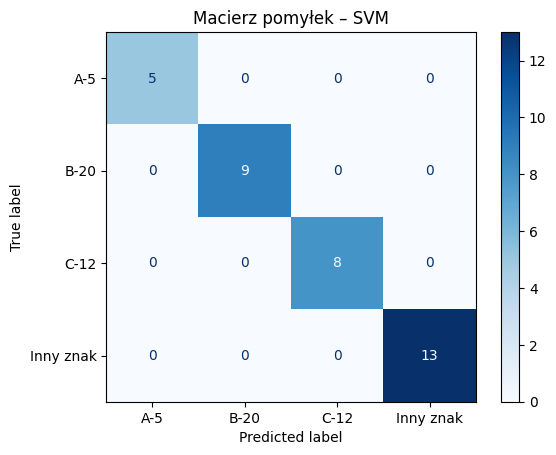

In [252]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print("Precision:", precision_score(y_test, y_pred_svm, average="macro", zero_division=0))
print("Recall:", recall_score(y_test, y_pred_svm, average="macro", zero_division=0))
print("F1-score:", f1_score(y_test, y_pred_svm, average="macro", zero_division=0))

print(classification_report(y_test, y_pred_svm, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_svm,
    labels=clf_svm.classes_,
    cmap="Blues",
    values_format="d"
)

plt.title("Macierz pomyłek – SVM")
plt.show()

In [ ]:
bledne_indeksy = np.where(
    y_pred_svm != y_test.to_numpy()
)[0]

df_bledne = df_klasyfikacja.loc[
    X_test.index[bledne_indeksy],
    ["zdjecie_id", "roi_id", "etykieta"]
].copy()

df_bledne["predykcja"] = y_pred_svm[bledne_indeksy]

display(df_bledne)
for _, wiersz in df_bledne.iterrows():
    i = wiersz["zdjecie_id"]
    j = wiersz["roi_id"]

    roi = obszary_roi[i][j]["roi"]

    plt.figure(figsize=(5, 5))
    plt.imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))

    plt.title(
        f"Zdjęcie {i} | ROI {j}\n"
        f"Prawdziwa: {wiersz['etykieta']} | "
        f"Predykcja: {wiersz['predykcja']}"
    )

    plt.axis("off")
    plt.show()

## 9. Analiza błędów segmentacji

In [ ]:
indeksy_zdjec_odrzuconych = [
    # Znaki zakazu
    15, 23, 24, 37, 38, 41, 43, 53, 68,

    # Znaki nakazu
    79, 80, 81, 83, 84, 90, 100, 101,
    111, 112, 128, 129, 130, 131, 140, 150,

    # Znaki ostrzegawcze
    154, 155, 165, 168, 169, 184
]

In [ ]:
kolumny = 4

for zdjecie_id in indeksy_zdjec_odrzuconych:

    obraz = przetworzone[zdjecie_id].copy()
    roi_zdjecia = obszary_roi[zdjecie_id]

    # Zaznaczenie wszystkich ROI na zdjęciu
    for roi_id, obiekt in enumerate(roi_zdjecia):

        x = obiekt["x"]
        y = obiekt["y"]
        w = obiekt["w"]
        h = obiekt["h"]

        cv2.rectangle(
            obraz,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        cv2.putText(
            obraz,
            str(roi_id),
            (x, max(y - 5, 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            (0, 255, 0),
            2
        )

    # Jedno zdjęcie + wszystkie jego ROI
    liczba_obrazow = 1 + len(roi_zdjecia)
    wiersze = math.ceil(liczba_obrazow / kolumny)

    fig, axes = plt.subplots(
        wiersze,
        kolumny,
        figsize=(16, wiersze * 4),
        squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    # Całe zdjęcie
    axes.flat[0].imshow(
        cv2.cvtColor(obraz, cv2.COLOR_BGR2RGB)
    )
    axes.flat[0].set_title(f"Zdjęcie {zdjecie_id}")

    # Wszystkie ROI zdjęcia
    for roi_id, obiekt in enumerate(roi_zdjecia):

        roi = obiekt["roi"]

        axes.flat[roi_id + 1].imshow(
            cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)
        )

        axes.flat[roi_id + 1].set_title(
            f"ROI {roi_id}"
        )

    plt.tight_layout()
    plt.show()
    plt.close(fig)

In [ ]:
Odrzucone roi które wymagają uwagi to:

indeks_zdjecia, indeks_roi
* 15,1 - znak stop z zbyt dużą ilością tła
* 38,3 - ucięty znak zakazu prawdopodobnie przez lampę na górze
* 41 - w ogóle nie znaleziono znaku stop najpewniej dlatego że
  odsiewamy konury o powierzni miejszej niż 0,1% całej maski
  prog = maski[0].shape[0] * maski[0].shape[1] * 0.001
* 53 - znak ucięty
* 68, 3 - za dużo tła
* 80, 5 - ucięty w połowie
* 83,3 - sklejony z innym znakiem o tym samym kolorze
* 90 - przy tym znaku droga rowerowa znalzeziono osobno góre i dół
* 128 - niebo w kolorzez znaku (znak z dużą iością tła)
* 150 niebo w kolorze znaku
* 154, 3 oraz 155, 4 - odrzuciłem już po segmentacji dlatego że kontur zewnętrzny nie obejmował znaku przez pomarańczowe tło
* 165, 2 - to maska czerwona dla znaku ostrzegawczego żółta wypadła jeszcze gorzej, usunąłem po wizualizacji konturów zewnętrznych i wewnętrznych


## testy

In [246]:
test_zdjęcie = (cv2.cvtColor(przetworzone[154], cv2.COLOR_BGR2HSV)).copy()


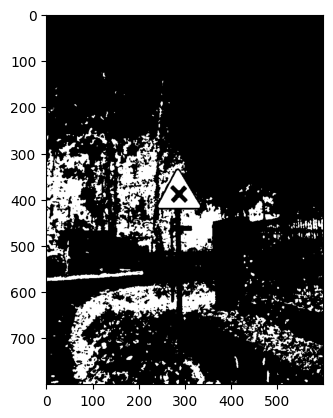

In [247]:
dolna_zolta = np.array([18, 90, 80])
gorna_zolta = np.array([35, 255, 255])
dolna_zolta = np.array([10, 100 , 70])
gorna_zolta = np.array([35,  255, 255])

# dolna_zolta = np.array([5, 100 , 70])
# gorna_zolta = np.array([45,  255, 255])

# dolna_zolta = np.array([15, 80, 70])
# gorna_zolta = np.array([35, 255, 255])
_,_,test_maska = tworzenie_masek(test_zdjęcie)
plt.imshow(test_maska,cmap="gray")

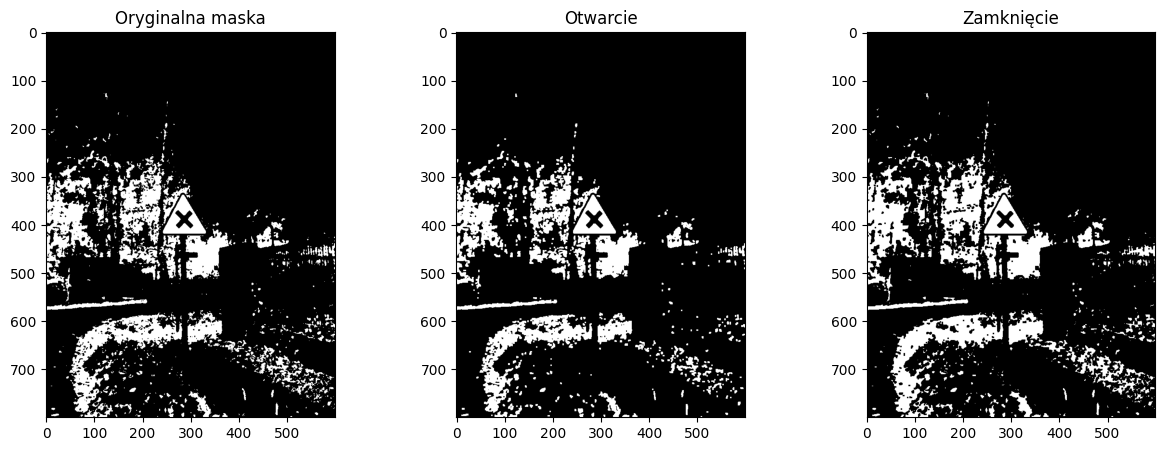

In [248]:
_, _, test_maska = tworzenie_masek(test_zdjęcie)

# jadro = cv2.getStructuringElement(
#     cv2.MORPH_ELLIPSE, (3, 3)
# )
kernel_3 = np.ones((3, 3), dtype=np.uint8)
kernel_5 = np.ones((5, 5), dtype=np.uint8)

test_maska_otwarcie = cv2.morphologyEx(
    test_maska, cv2.MORPH_OPEN, kernel_3
)

test_maska_zamkniecie = cv2.morphologyEx(
    test_maska, cv2.MORPH_CLOSE, kernel_3
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(test_maska, cmap="gray")
plt.title("Oryginalna maska")

plt.subplot(1, 3, 2)
plt.imshow(test_maska_otwarcie, cmap="gray")
plt.title("Otwarcie")

plt.subplot(1, 3, 3)
plt.imshow(test_maska_zamkniecie, cmap="gray")
plt.title("Zamknięcie")

plt.show()

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(800, 600), dtype=uint8)
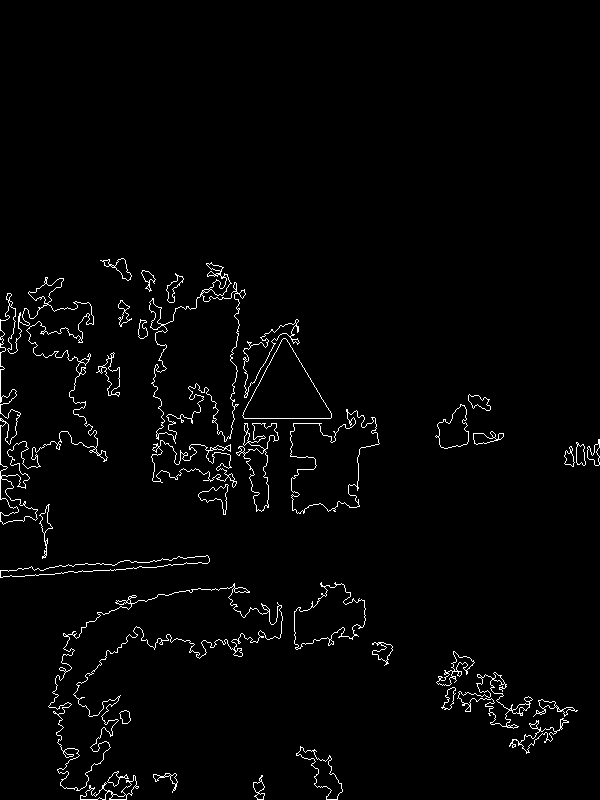

In [249]:
kontury_test,_ = cv2.findContours(test_maska,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)

kontury_test = [
    k for k in kontury_test
    if cv2.contourArea(k) > 100
]

maska_po_filtracji_test = np.zeros_like(test_maska)

cv2.drawContours(maska_po_filtracji_test,kontury_test,-1,(255,0,0),1)

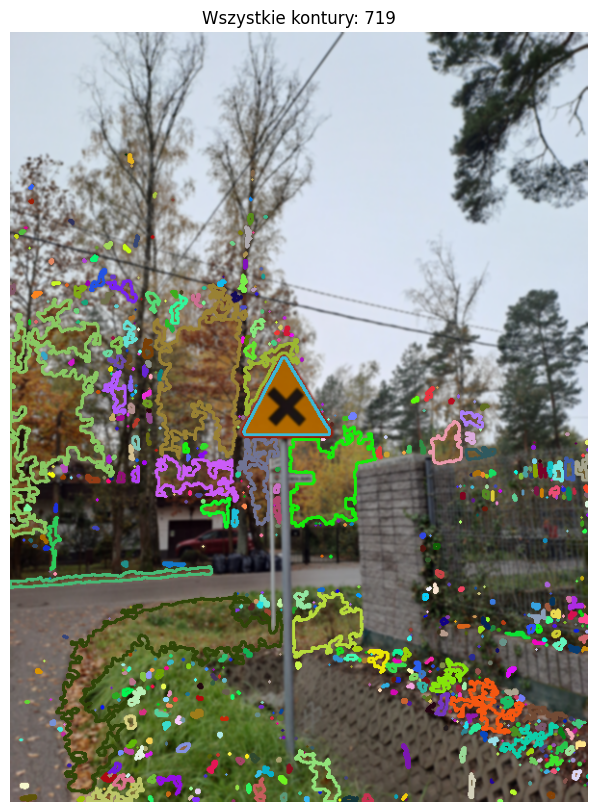

In [250]:
kontury_test, _ = cv2.findContours(
    test_maska,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

podglad_test = cv2.cvtColor(
    przetworzone[154], cv2.COLOR_BGR2RGB
).copy()

for indeks, kontur in enumerate(kontury_test):
    kolor = tuple(
        int(x) for x in np.random.randint(0, 256, 3)
    )

    cv2.drawContours(
        podglad_test,
        [kontur],
        -1,
        kolor,
        2
    )

plt.figure(figsize=(10, 10))
plt.imshow(podglad_test)
plt.title(f"Wszystkie kontury: {len(kontury_test)}")
plt.axis("off")
plt.show()